# Coronary Artery Disease Risk Model: UCI Cleveland Heart Disease Data

**Question:** How well do routinely collected clinical and exercise-test variables identify angiographic coronary artery disease, and are the predicted probabilities trustworthy enough to use as risk estimates?

**Data:** the Cleveland Clinic subset of the UCI *Heart Disease* dataset (Janosi, Steinbrunn, Pfisterer & Detrano, 1989; CC BY 4.0). 303 patients referred for coronary angiography. The outcome is **any major vessel with >50% diameter narrowing** (`num` > 0).

> Research and education only. This isn't a clinical decision tool.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from heart import (BINARY, CATEGORICAL, FEATURES, NUMERIC, bootstrap_ci, load_cleveland, make_model,
                   make_preprocessor, repeated_cv, screening_metrics, sha256)

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.float_format", "{:.3f}".format)
RAW = ROOT / "data" / "raw" / "heart_disease_uci45.zip"
FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, INK2, GRID = "#2a78d6", "#eb6834", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
                     "axes.grid": True, "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.labelcolor": INK2, "lines.linewidth": 2,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})

## 1. Data

In [2]:
assert sha256(RAW) == "b17cd273da9ce1caa4710fce80227ea454d4dbf9fcbc8e6a9121672751563adc"
df = load_cleveland(RAW)
y = df["disease"].values
X = df[FEATURES]
print(f"{len(df)} patients; coronary disease (num > 0): {y.sum()} ({y.mean():.1%}); "
      f"missing: ca {df['ca'].isna().sum()}, thal {df['thal'].isna().sum()}")
pd.concat([df.groupby("disease")[NUMERIC].mean().T.rename(columns={0: "no disease (mean)", 1: "disease (mean)"})], axis=1)

303 patients; coronary disease (num > 0): 139 (45.9%); missing: ca 4, thal 2


disease,no disease (mean),disease (mean)
age,52.585,56.626
trestbps,129.250,134.568
chol,242.640,251.475
thalach,158.378,139.259
oldpeak,0.587,1.574
ca,0.273,1.138


In [3]:
pd.crosstab(df["cp"], df["disease"], normalize="index").rename(columns={0: "no disease", 1: "disease"})

disease,no disease,disease
cp,,
asymptomatic,0.271,0.729
atypical angina,0.820,0.180
non-anginal pain,0.791,0.209
typical angina,0.696,0.304


Note the chest-pain pattern: in this referral population, **asymptomatic** patients have the highest disease rate. That's a known feature of the Cleveland cohort, not a coding error. The widely shared Kaggle `heart.csv` renumbers these categories, and its `target` column is **inverted** (1 = no disease); see the README.

## 2. Models and validation

* **Primary model:** L2-regularized logistic regression. It's interpretable and gives probability outputs.
* **Comparison:** random forest (500 trees, min 5 samples per leaf).
* **Preprocessing inside every fold:** median imputation and scaling for continuous variables; mode imputation and one-hot encoding for chest-pain type, resting ECG, ST slope and thallium result.
* **Validation:** stratified 5-fold CV repeated 20 times, using out-of-fold predicted probabilities.
* **Two operating points:** a fixed 0.5 threshold, and a threshold chosen **inside each training fold** (from inner 5-fold CV) to reach **90% sensitivity**, the kind of rule-out setting where missing disease is the costly error.

In [4]:
models = {
    "Logistic regression (primary)": lambda: make_model(LogisticRegression(max_iter=2000)),
    "Random forest": lambda: make_model(RandomForestClassifier(n_estimators=500, min_samples_leaf=5, random_state=0)),
}
cv_results = {name: repeated_cv(f, X, y, n_repeats=20, target_sensitivity=0.90) for name, f in models.items()}

rows = {}
for name, reps in cv_results.items():
    auc, lo, hi = bootstrap_ci(roc_auc_score, y, reps[0]["proba"])
    rows[name] = {
        "ROC-AUC (mean of 20 repeats)": np.mean([roc_auc_score(y, r["proba"]) for r in reps]),
        "ROC-AUC 95% CI (repeat 1)": f"{lo:.3f} to {hi:.3f}",
        "PR-AUC": np.mean([average_precision_score(y, r["proba"]) for r in reps]),
        "Brier score": np.mean([brier_score_loss(y, r["proba"]) for r in reps]),
    }
discrimination = pd.DataFrame(rows).T
print(f"Reference Brier score for always predicting the prevalence: {y.mean() * (1 - y.mean()):.3f}")
discrimination

Reference Brier score for always predicting the prevalence: 0.248


,ROC-AUC (mean of 20 repeats),ROC-AUC 95% CI (repeat 1),PR-AUC,Brier score
Logistic regression (primary),0.907,0.874 to 0.940,0.899,0.118
Random forest,0.898,0.865 to 0.931,0.891,0.132


In [5]:
rows = []
for name, reps in cv_results.items():
    for label, key in [("threshold 0.5", "flag_05"), ("threshold for 90% sensitivity (chosen in training folds)", "flag_target")]:
        m = pd.DataFrame([screening_metrics(y, r[key]) for r in reps]).mean()
        rows.append({"model": name, "operating point": label, **m.to_dict()})
operating = pd.DataFrame(rows).set_index(["model", "operating point"])
operating

sensitivity  \
model                         operating point                                                   
Logistic regression (primary) threshold 0.5                                             0.792   
                              threshold for 90% sensitivity (chosen in traini...        0.896   
Random forest                 threshold 0.5                                             0.782   
                              threshold for 90% sensitivity (chosen in traini...        0.893   

                                                                                  specificity  \
model                         operating point                                                   
Logistic regression (primary) threshold 0.5                                             0.886   
                              threshold for 90% sensitivity (chosen in traini...        0.704   
Random forest                 threshold 0.5                                             0.842   
                              threshold for 90% sensitivity (chosen in traini...        0.660   

                                                                                   PPV  \
model                         operating point                                            
Logistic regression (primary) threshold 0.5                                      0.855   
                              threshold for 90% sensitivity (chosen in traini... 0.720   
Random forest                 threshold 0.5                                      0.808   
                              threshold for 90% sensitivity (chosen in traini... 0.690   

                                                                                   NPV  
model                         operating point                                           
Logistic regression (primary) threshold 0.5                                      0.834  
                              threshold for 90% sensitivity (chosen in traini... 0.889  
Random forest                 threshold 0.5                                      0.820  
                              threshold for 90% sensitivity (chosen in traini... 0.879

## 3. Calibration

A risk model should be calibrated as well as discriminating: among patients given a 30% risk, about 30% should have disease. The plot uses out-of-fold probabilities from the first CV repeat, grouped into five quantile bins.

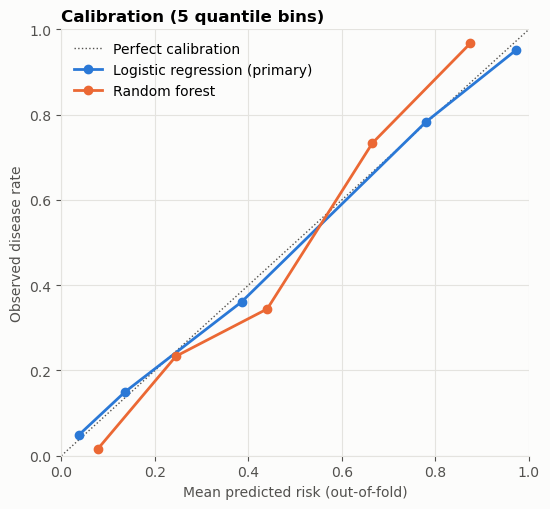

In [6]:
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 1], [0, 1], color=INK2, linestyle=":", linewidth=1, label="Perfect calibration")
for (name, reps), color in zip(cv_results.items(), [BLUE, ORANGE]):
    frac, mean_pred = calibration_curve(y, reps[0]["proba"], n_bins=5, strategy="quantile")
    ax.plot(mean_pred, frac, color=color, marker="o", markersize=6, label=name)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Mean predicted risk (out-of-fold)")
ax.set_ylabel("Observed disease rate")
ax.set_title("Calibration (5 quantile bins)")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(FIGS / "calibration.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Interpretation: adjusted odds ratios

An unpenalized logistic regression on the 297 complete cases. Continuous variables are standardized, so their odds ratios are **per 1 standard deviation**; categorical variables are compared with the most common level as reference (asymptomatic chest pain, normal resting ECG, upsloping ST segment, normal thallium scan); `sex` is male vs female. These are adjusted associations in a referral cohort, not causal effects.

In [7]:
cc = df.dropna(subset=FEATURES)
reference = {"cp": "asymptomatic", "restecg": "normal", "slope": "upsloping", "thal": "normal"}
cats = pd.DataFrame({c: pd.Categorical(cc[c], categories=[reference[c]] + sorted(set(cc[c]) - {reference[c]}))
                     for c in CATEGORICAL}, index=cc.index)
design = pd.get_dummies(cats, drop_first=True, dtype=float)
print("Patients per category:", {c: cc[c].value_counts().to_dict() for c in CATEGORICAL})
cont = (cc[NUMERIC] - cc[NUMERIC].mean()) / cc[NUMERIC].std()
Xs = sm.add_constant(pd.concat([cont, cc[BINARY].astype(float), design], axis=1))
fit = sm.Logit(cc["disease"], Xs).fit(disp=False)
sd = cc[NUMERIC].std()
odds = pd.DataFrame({"odds ratio": np.exp(fit.params), "95% CI low": np.exp(fit.conf_int()[0]),
                     "95% CI high": np.exp(fit.conf_int()[1]), "p-value": fit.pvalues}).drop("const")
odds["unit"] = [f"per {sd[i]:.1f} (1 SD)" if i in NUMERIC else "male vs female" if i == "sex" else "yes vs no" if i in BINARY else "vs reference" for i in odds.index]
odds.sort_values("odds ratio", ascending=False)

Patients per category: {'cp': {'asymptomatic': 142, 'non-anginal pain': 83, 'atypical angina': 49, 'typical angina': 23}, 'restecg': {'normal': 147, 'LV hypertrophy': 146, 'ST-T abnormality': 4}, 'slope': {'upsloping': 139, 'flat': 137, 'downsloping': 21}, 'thal': {'normal': 164, 'reversible defect': 115, 'fixed defect': 18}}


,odds ratio,95% CI low,95% CI high,p-value,unit
sex,4.693,1.661,13.260,0.004,male vs female
thal_reversible defect,4.026,1.750,9.263,0.001,vs reference
ca,3.426,2.049,5.728,0.000,per 0.9 (1 SD)
slope_flat,3.175,1.254,8.036,0.015,vs reference
restecg_ST-T abnormality,2.248,0.019,265.852,0.739,vs reference
exang,2.033,0.858,4.816,0.107,yes vs no
slope_downsloping,1.691,0.279,10.254,0.568,vs reference
restecg_LV hypertrophy,1.606,0.757,3.406,0.217,vs reference
trestbps,1.542,1.041,2.282,0.031,per 17.8 (1 SD)
oldpeak,1.518,0.897,2.568,0.120,per 1.2 (1 SD)


## 5. Findings

1. **Discrimination is good and the simple model wins.** Logistic regression reached a mean cross-validated ROC-AUC of **0.907** (95% CI 0.874–0.940) versus 0.898 for the random forest. Its Brier score was 0.118, against 0.248 for predicting the prevalence for everyone.
2. **Logistic regression is well calibrated.** Its predicted risks track observed disease rates across the range. The random forest is less calibrated at the extremes, which matters if the output is used as a probability.
3. **The operating point is a clinical choice.** At a 0.5 threshold, the primary model had sensitivity 0.792 and specificity 0.886. A threshold chosen inside training folds for 90% sensitivity achieved **0.896 sensitivity** on held-out patients at the cost of specificity (0.704); NPV rose from 0.834 to 0.889.
4. **Strongest adjusted associations:** number of major vessels coloured on fluoroscopy (OR 3.43 per SD), a reversible thallium defect (OR 4.03 vs normal), flat ST slope (OR 3.18 vs upsloping), male sex (OR 4.69), and higher resting blood pressure (OR 1.54 per SD). Typical (OR 0.12) and non-anginal (OR 0.16) chest pain carried *lower* odds than asymptomatic presentation in this referral cohort. Several estimates have wide intervals; ST-T abnormality has only 4 patients.

## 6. Limitations

* **Referral population.** These patients were already sent for angiography (46% prevalence), so PPV/NPV and the chest-pain pattern don't transfer to general screening.
* **1980s single-centre data (Cleveland Clinic), n = 303.** There's no external validation here. The other UCI sites (Hungary, Switzerland, Long Beach VA) would be the natural next test.
* **Two features come from invasive or specialist tests** (fluoroscopy vessel count and thallium scan), so the model isn't a primary-care risk score.
* **Binary outcome:** disease severity (`num` 1–4) is collapsed into "any vessel > 50% narrowed".
* **Confidence intervals** for discrimination use one CV repeat's out-of-fold predictions; the means are over all 20 repeats.